In [1]:
import pandas as pd
df = pd.read_csv("../data/data.csv", encoding="ISO-8859-1")
print(df.shape)
df.head()


(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12-01-2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12-01-2010 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12-01-2010 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12-01-2010 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12-01-2010 08:26,3.39,17850.0,United Kingdom


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Load data using relative path
df = pd.read_csv("../data/data.csv", encoding="ISO-8859-1")
print("Original shape:", df.shape)


Original shape: (541909, 8)


In [2]:
df.info()
print("\nMissing values per column:")
print(df.isnull().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB

Missing values per column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [5]:
rows_start = len(df)

# 1. Remove rows with no customer ID 
df = df.dropna(subset=["CustomerID"])
print("After removing missing CustomerID:", len(df))

# 2. Remove duplicate rows
df = df.drop_duplicates()
print("After removing duplicates:", len(df))

# 3. Remove cancelled orders (invoice numbers starting with 'C')
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]
print("After removing cancellations:", len(df))

# 4. Remove negative or zero quantity and price
df = df[(df["Quantity"] > 0) & (df['UnitPrice'] > 0)]
print("After removing bad quantity/price:", len(df))

# 5. Fix data types and add a Revenue column
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], format='mixed')
df["CustomerID"] = df["CustomerID"].astype(int)
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

print(f"\nStarted with {rows_start} rows, ended with {len(df)} rows")
df.head()


After removing missing CustomerID: 392692
After removing duplicates: 392692
After removing cancellations: 392692
After removing bad quantity/price: 392692

Started with 392692 rows, ended with 392692 rows


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [6]:
print("Total revenue:", round(df["Revenue"].sum(), 2))
print("Unique customers:", df["CustomerID"].nunique())
print("Unique orders:", df["InvoiceNo"].nunique())
print("Unique products:", df["StockCode"].nunique())
print("Date range:", df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())
print("Average order value:", round(df.groupby("InvoiceNo")["Revenue"].sum().mean(), 2))


Total revenue: 8887208.89
Unique customers: 4338
Unique orders: 18532
Unique products: 3665
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00
Average order value: 479.56


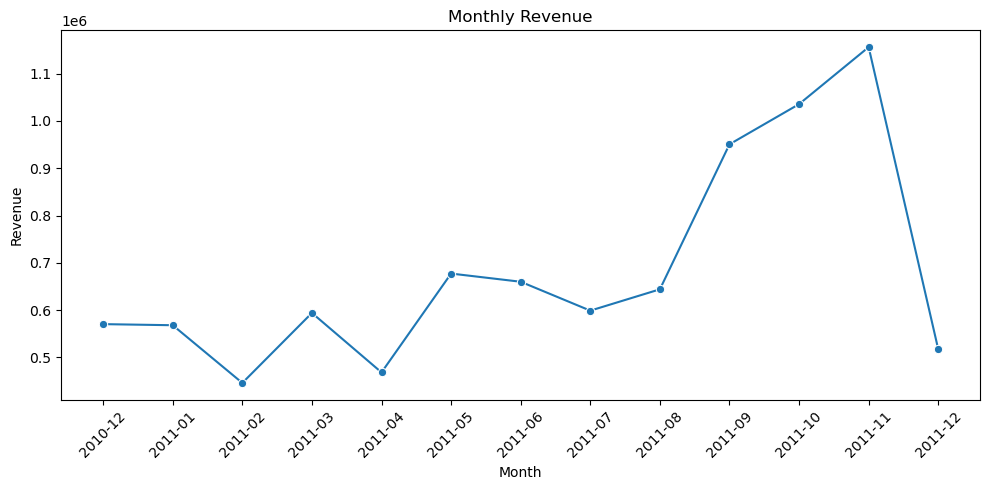

In [7]:
df["Month"] = df["InvoiceDate"].dt.to_period("M").astype(str)
monthly = df.groupby("Month")["Revenue"].sum().reset_index()

plt.figure(figsize=(10, 5))
sns.lineplot(data=monthly, x="Month", y="Revenue", marker="o")
plt.xticks(rotation=45)
plt.title("Monthly Revenue")
plt.tight_layout()
plt.savefig("../images/monthly_revenue.png", dpi=150)
plt.show()


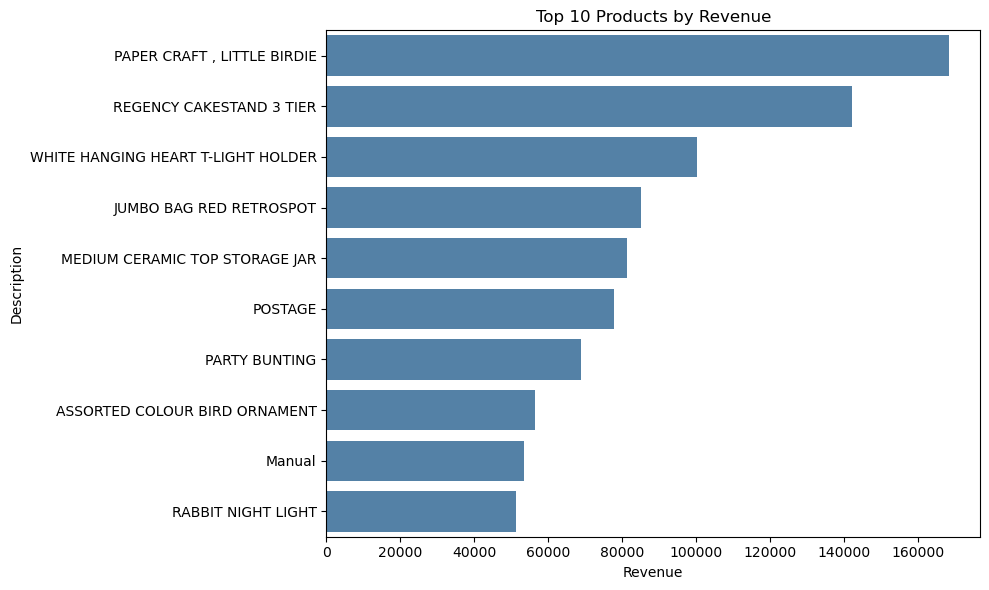

In [8]:
top = df.groupby("Description")["Revenue"].sum().nlargest(10).reset_index()

plt.figure(figsize=(10, 6))
sns.barplot(data=top, x="Revenue", y="Description", color="steelblue")
plt.title("Top 10 Products by Revenue")
plt.tight_layout()
plt.savefig("../images/top_products.png", dpi=150)
plt.show()


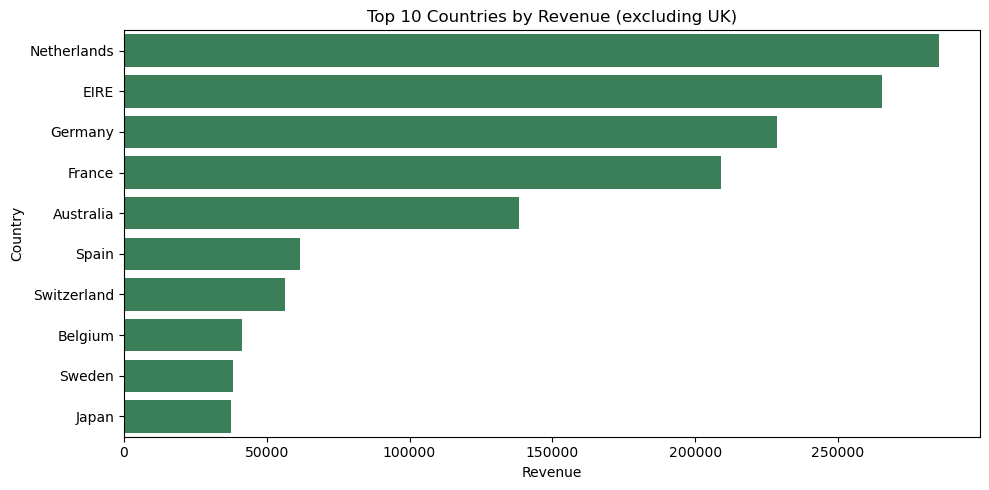

UK share of revenue: 82.0%


In [9]:
countries = (df[df["Country"] != "United Kingdom"]
             .groupby("Country")["Revenue"].sum().nlargest(10).reset_index())

plt.figure(figsize=(10, 5))
sns.barplot(data=countries, x="Revenue", y="Country", color="seagreen")
plt.title("Top 10 Countries by Revenue (excluding UK)")
plt.tight_layout()
plt.savefig("../images/top_countries.png", dpi=150)
plt.show()

uk_share = df[df["Country"] == "United Kingdom"]["Revenue"].sum() / df["Revenue"].sum()
print(f"UK share of revenue: {uk_share:.1%}")


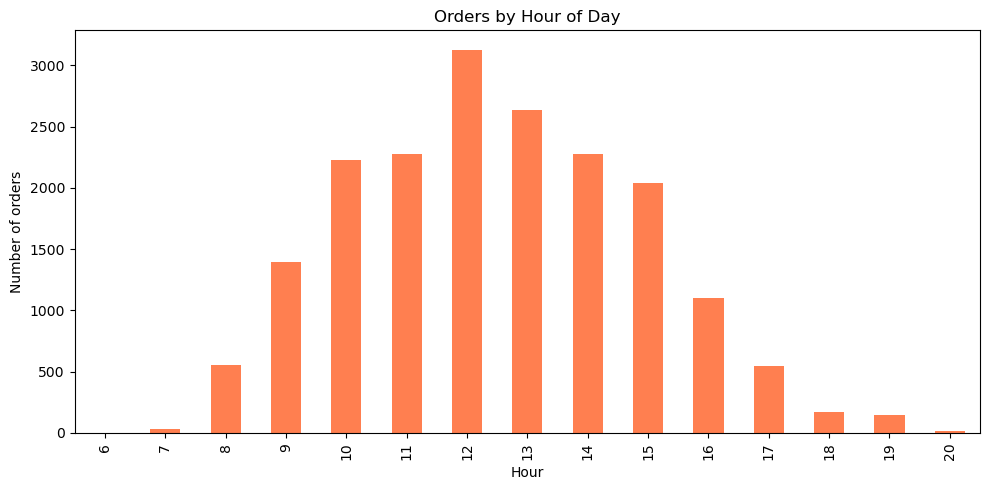

In [10]:
df["Hour"] = df["InvoiceDate"].dt.hour
df["DayOfWeek"] = df["InvoiceDate"].dt.day_name()

hourly = df.groupby("Hour")["InvoiceNo"].nunique()
plt.figure(figsize=(10, 5))
hourly.plot(kind="bar", color="coral")
plt.title("Orders by Hour of Day")
plt.ylabel("Number of orders")
plt.tight_layout()
plt.savefig("../images/orders_by_hour.png", dpi=150)
plt.show()


In [11]:
fig = px.line(monthly, x="Month", y="Revenue", title="Monthly Revenue (interactive)", markers=True)
fig.show()


In [12]:
df.to_csv("../data/cleaned_data.csv", index=False)
print("Cleaned file saved successfully.")


Cleaned file saved successfully.


In [13]:
df.to_csv("../data/cleaned_data.csv", index=False)
print("Cleaned data file saved successfully in data/ folder.")


Cleaned data file saved successfully in data/ folder.


In [14]:
# Set a baseline timeline anchor point (1 day past the maximum invoice date)
snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

# Group transactions by customer to compile baseline RFM metrics
rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum")
).reset_index()

print("RFM Matrix Dimensions:", rfm.shape)
rfm.describe()


RFM Matrix Dimensions: (4338, 4)


,CustomerID,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000,4338.000000
mean,15300.408022,92.536422,4.272015,2048.688081
std,1721.808492,100.014169,7.697998,8985.230220
min,12346.000000,1.000000,1.000000,3.750000
25%,13813.250000,18.000000,1.000000,306.482500
50%,15299.500000,51.000000,2.000000,668.570000
75%,16778.750000,142.000000,5.000000,1660.597500
max,18287.000000,374.000000,209.000000,280206.020000


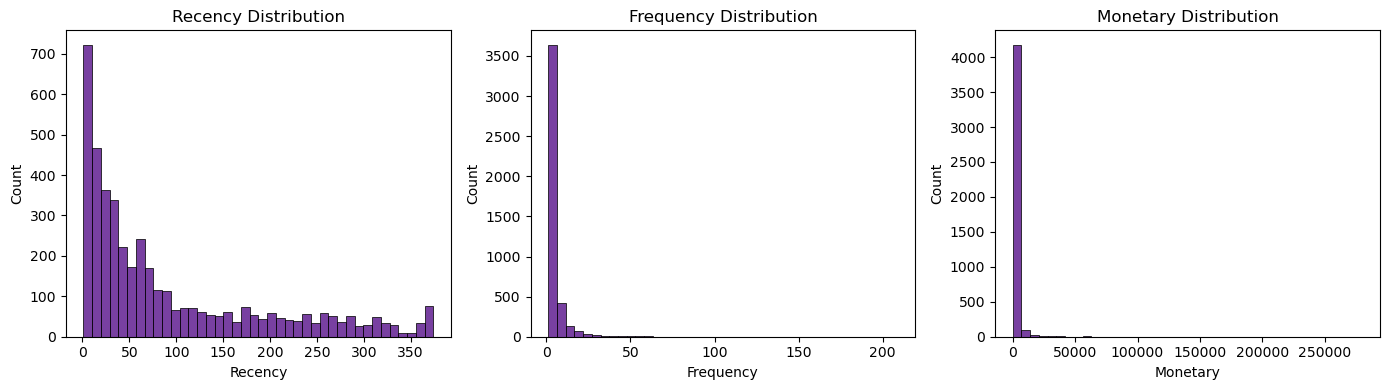

In [15]:
# Visualize the distributional spread across metrics
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["Recency", "Frequency", "Monetary"]):
    sns.histplot(rfm[col], bins=40, ax=ax, color="indigo")
    ax.set_title(f"{col} Distribution")
plt.tight_layout()
plt.savefig("../images/rfm_distributions.png", dpi=150)
plt.show()


In [16]:
from sklearn.preprocessing import StandardScaler

# Log transform metrics using log1p to manage zero-index skew variations smoothly
rfm_log = np.log1p(rfm[["Recency", "Frequency", "Monetary"]])

# Scale metrics into unit variance (z-score scaling normalization)
X_scaled = StandardScaler().fit_transform(rfm_log)
print("Standardized Data Matrix Shape:", X_scaled.shape)


Standardized Data Matrix Shape: (4338, 3)


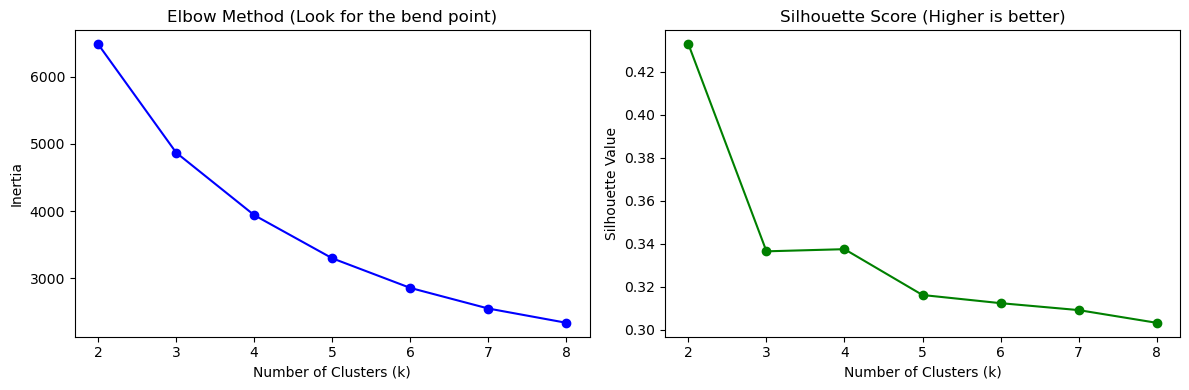

In [18]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia, sil = [], []
K = range(2, 9)

# Iteratively evaluate variance and cohesion metrics for cluster ranges
for k in K:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X_scaled, km.labels_))

# Plot evaluation metrics dashboard
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(K, inertia, marker="o", color="blue")
ax[0].set_title("Elbow Method (Look for the bend point)")
ax[0].set_xlabel("Number of Clusters (k)")
ax[0].set_ylabel("Inertia")

ax[1].plot(K, sil, marker="o", color="green")
ax[1].set_title("Silhouette Score (Higher is better)")
ax[1].set_xlabel("Number of Clusters (k)")
ax[1].set_ylabel("Silhouette Value")
plt.tight_layout()
plt.savefig("../images/choose_k.png", dpi=150)
plt.show()


In [19]:
# Initialize and predict final labels
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm["Cluster"] = kmeans.fit_predict(X_scaled)

# Aggregate profiles to discover cluster core properties
profile = rfm.groupby("Cluster").agg(
    Customers=("CustomerID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Total_Revenue=("Monetary", "sum")
).round(1)

profile["Revenue_Share_%"] = (profile["Total_Revenue"] / profile["Total_Revenue"].sum() * 100).round(1)
profile


,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue,Revenue_Share_%
Cluster,,,,,,
0,713,12.2,13.8,8088.0,5766757.1,64.9
1,1622,181.5,1.3,341.0,553099.8,6.2
2,837,17.7,2.2,557.3,466479.0,5.2
3,1166,71.6,4.1,1801.8,2100873.0,23.6


In [20]:
# EXAMINE YOUR PROFILE TABLE: Match the labels based on real mean values
# Example Mapping (Verify your cluster index traits first!):
# Champions = Lowest Recency, Highest Frequency, Highest Monetary
# At-Risk/Lost = Highest Recency, Lowest Frequency, Lowest Monetary
segment_names = {
    0: "Loyal Customers",
    1: "At-Risk / Lost",
    2: "Champions",
    3: "New / Occasional"
}

rfm["Segment"] = rfm["Cluster"].map(segment_names)
print(rfm["Segment"].value_counts())


Segment
At-Risk / Lost      1622
New / Occasional    1166
Champions            837
Loyal Customers      713
Name: count, dtype: int64


C:\Users\Dasari Pallavi\AppData\Local\Temp\ipykernel_14192\1351756558.py:7: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


C:\Users\Dasari Pallavi\AppData\Local\Temp\ipykernel_14192\1351756558.py:11: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




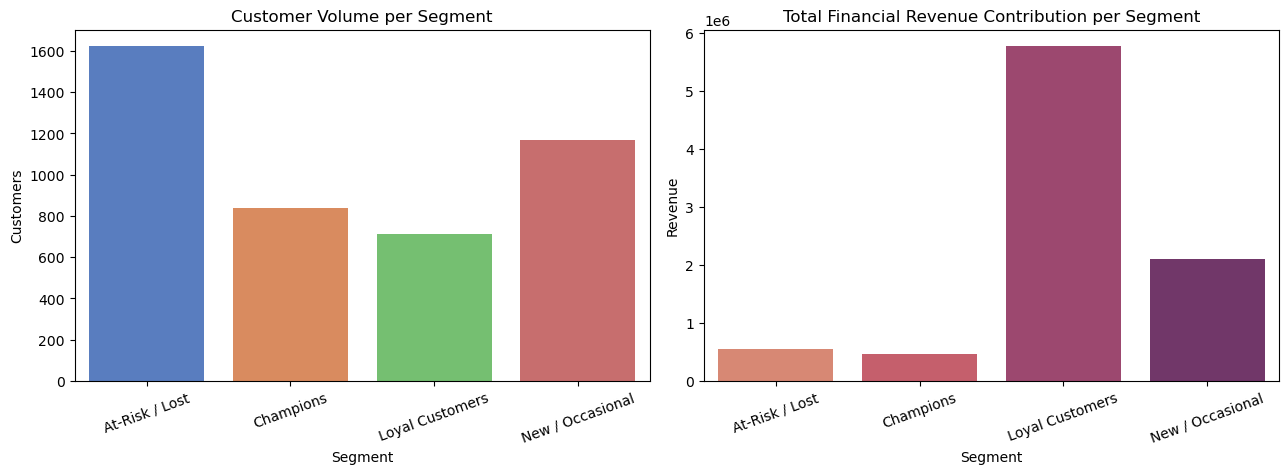

In [21]:
seg_summary = rfm.groupby("Segment").agg(
    Customers=("CustomerID", "count"),
    Revenue=("Monetary", "sum")
).reset_index()

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=seg_summary, x="Segment", y="Customers", ax=ax[0], palette="muted")
ax[0].set_title("Customer Volume per Segment")
ax[0].tick_params(axis="x", rotation=20)

sns.barplot(data=seg_summary, x="Segment", y="Revenue", ax=ax[1], palette="flare")
ax[1].set_title("Total Financial Revenue Contribution per Segment")
ax[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig("../images/segment_summary.png", dpi=150)
plt.show()


In [22]:
fig = px.scatter_3d(rfm, x="Recency", y="Frequency", z="Monetary",
                    color="Segment", opacity=0.7,
                    title="Customer Segments (Interactive 3D RFM Model)")
fig.show()


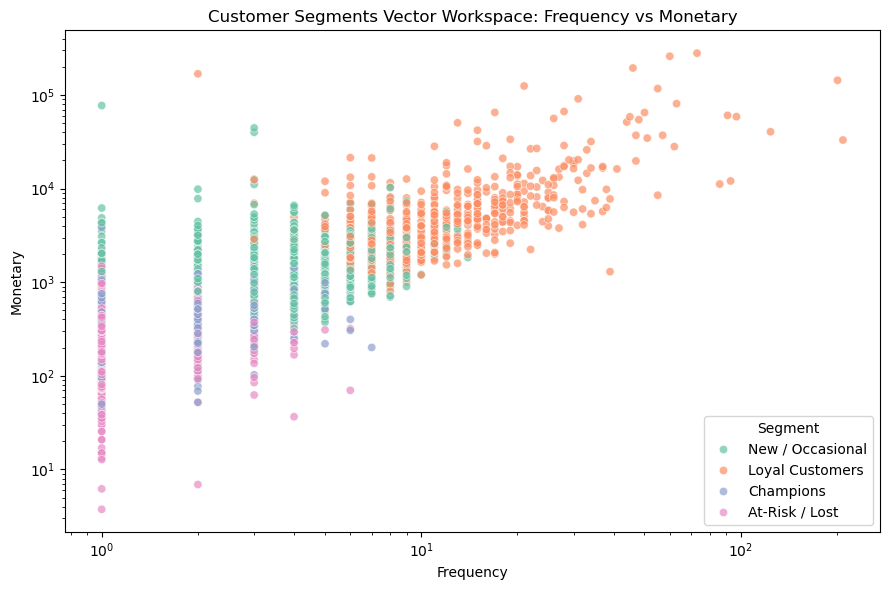

In [23]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=rfm, x="Frequency", y="Monetary", hue="Segment", alpha=0.7, palette="Set2")
plt.xscale("log")
plt.yscale("log")
plt.title("Customer Segments Vector Workspace: Frequency vs Monetary")
plt.tight_layout()
plt.savefig("../images/segments_scatter.png", dpi=150)
plt.show()


In [ ]:
rfm.to_csv("../data/customer_segments.csv", index=False)
print("Customer segment data saved locally.")
